In [1]:
!pip install tensorflow


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np
import random

In [3]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train / 255.0
x_test = x_test / 255.0

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step 


In [4]:
model = Sequential()
model.add(tf.keras.layers.Flatten(input_shape=(28, 28)))
model.add(tf.keras.layers.Dense(128, activation='relu'))
model.add(tf.keras.layers.Dense(10, activation='softmax'))

model.compile(
    optimizer='sgd',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

H = model.fit(
    x_train,
    y_train,
    validation_data=(x_test, y_test),
    epochs=5
)

C:\Users\abhis\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8419 - loss: 0.6274 - val_accuracy: 0.9013 - val_loss: 0.3545
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9053 - loss: 0.3359 - val_accuracy: 0.9179 - val_loss: 0.2912
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9187 - loss: 0.2885 - val_accuracy: 0.9261 - val_loss: 0.2604
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9273 - loss: 0.2587 - val_accuracy: 0.9318 - val_loss: 0.2387
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9335 - loss: 0.2367 - val_accuracy: 0.9361 - val_loss: 0.2215


In [5]:
test_loss, test_acc = model.evaluate(x_test, y_test)

print("Loss = %.3f" % test_loss)
print("Accuracy = %.3f" % test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9361 - loss: 0.2215 
Loss = 0.222
Accuracy = 0.936


In [1]:
n = random.randint(0, 9999)
plt.imshow(x_test[n])
plt.show()

NameError: name 'random' is not defined

In [7]:
prediction = model.predict(x_test)
print("The handwritten number in the image is %d" % np.argmax(prediction[n]))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step  
The handwritten number in the image is 7


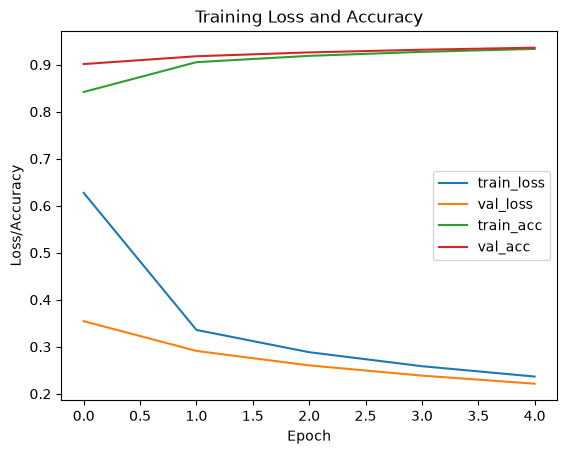

In [8]:
plt.plot(H.history['loss'], label='train_loss')
plt.plot(H.history['val_loss'], label='val_loss')
plt.plot(H.history['accuracy'], label='train_acc')
plt.plot(H.history['val_accuracy'], label='val_acc')
plt.title("Training Loss and Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Loss/Accuracy")
plt.legend()
plt.show()